In [1]:
import json, csv, time, zipfile
import numpy as np
from pathlib import Path

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent
EXTRACT_DIR = PROJECT_DIR / "data" / "sen2fire"
HIST_PATH = PROJECT_DIR / "data" / "baseline_hist.npz"
RF_PATH = PROJECT_DIR / "data" / "rf_samples.npz"

In [2]:
REF_ZIP = PROJECT_DIR / "data" / "reference" / "Baseline_code.zip"
REF_ZIP.parent.mkdir(parents=True, exist_ok=True)
print("Folder ready :", REF_ZIP.parent)
print("Zip present  :", REF_ZIP.exists())

if REF_ZIP.exists():
    with zipfile.ZipFile(REF_ZIP) as zf:
        for info in zf.infolist():
            print(f"{info.file_size:>10,d}  {info.filename}")
    with zipfile.ZipFile(REF_ZIP) as zf:
        text = zf.read("dataset/Sen2Fire_Dataset.py").decode("utf-8", errors="replace")

        for n, line in enumerate(text.splitlines(), start=1):
            print(f"{n:3d}  {line}")

Folder ready : g:\sen2fire-thesis\data\reference
Zip present  : True
         0  dataset/__init__.py
     7,083  dataset/Sen2Fire_Dataset.py
    15,721  dataset/test.txt
    45,682  dataset/train.txt
    15,676  dataset/val.txt
         0  model/__init__.py
     3,157  model/Networks.py
     8,301  Test.py
    13,787  Train.py
         0  utils/__init__.py
     2,769  utils/tools.py
  1  import os.path as osp
  2  import numpy as np
  3  from torch.utils import data
  4  from tqdm import tqdm
  5  
  6  modename = ['all_bands',                        #0
  7              'all_bands_aerosol',                #1
  8              'rgb',                              #2
  9              'rgb_aerosol',                      #3
 10              'swir',                             #4
 11              'swir_aerosol',                     #5
 12              'nbr',                              #6
 13              'nbr_aerosol',                      #7   
 14              'ndvi',                     

In [3]:
splits = {}
with zipfile.ZipFile(REF_ZIP) as zf:
    for name in ["train", "val", "test"]:
        raw = zf.read(f"dataset/{name}.txt").decode("utf-8")
        splits[name] = [line.strip() for line in raw.splitlines() if line.strip()]

for name, items in splits.items():
    scenes = sorted({Path(i).parts[0] if len(Path(i).parts) > 1 else "(no folder)" for i in items})
    print(f"{name:5s}: {len(items):5d} entries | first: {items[0]} | folders: {scenes}")

all_on_disk = {f"{s}/{p.name}" for s in ["scene1", "scene2", "scene3", "scene4"]
               for p in (EXTRACT_DIR / s).glob("*.npz")}

for name, items in splits.items():
    norm = [i.replace("\\", "/") for i in items]
    missing = [i for i in norm if i not in all_on_disk]
    print(f"{name:5s}: missing on disk = {len(missing)}", missing[:3])

sets = {k: {i.replace("\\", "/") for i in v} for k, v in splits.items()}
print("train & val overlap :", len(sets["train"] & sets["val"]))
print("train & test overlap:", len(sets["train"] & sets["test"]))
print("val & test overlap  :", len(sets["val"] & sets["test"]))
print("on disk but in no split:", len(all_on_disk - sets["train"] - sets["val"] - sets["test"]))

train:  1458 entries | first: scene1/scene_1_patch_1_1.npz | folders: ['scene1', 'scene2']
val  :   504 entries | first: scene3/scene_3_patch_1_1.npz | folders: ['scene3']
test :   504 entries | first: scene4/scene_4_patch_1_1.npz | folders: ['scene4']
train: missing on disk = 0 []
val  : missing on disk = 0 []
test : missing on disk = 0 []
train & val overlap : 0
train & test overlap: 0
val & test overlap  : 0
on disk but in no split: 0


In [4]:
rng = np.random.default_rng(0)

def sample_split(items, n_pos, n_neg, n_uniform):
    Xs, ys, ps = [], [], []
    t0 = time.perf_counter()
    for i, rel in enumerate(items):
        with np.load(EXTRACT_DIR / rel) as d_:
            img = d_["image"]
            aer = d_["aerosol"].ravel().astype(np.float32)
            lb = (d_["label"] > 0).ravel()
        X = img.reshape(img.shape[0], -1).astype(np.float32)
        N = X.shape[1]
        if n_uniform:
            idx = rng.integers(0, N, size=n_uniform)
        else:
            pos_all = np.flatnonzero(lb)
            pos = rng.choice(pos_all, size=min(n_pos, len(pos_all)), replace=False) if len(pos_all) else pos_all
            cand = rng.integers(0, N, size=n_neg * 2)
            neg = cand[~lb[cand]][:n_neg]
            idx = np.concatenate([pos, neg])
        ratio = (X[11, idx] / np.maximum(X[10, idx], 1.0))[:, None]
        feats = np.hstack([X[:, idx].T, ratio, aer[idx][:, None]]).astype(np.float32)
        Xs.append(feats)
        ys.append(lb[idx].astype(np.uint8))
        ps.append(np.full(len(idx), i, dtype=np.int32))
        if (i + 1) % 300 == 0:
            print(f"{len(items)} patches, {i + 1} done ({time.perf_counter() - t0:.0f} s)")
    return np.vstack(Xs), np.concatenate(ys), np.concatenate(ps)

if RF_PATH.exists():
    print("Cache already exists, skipping.")
else:
    Xtr, ytr, ptr_id = sample_split(splits["train"], 1000, 1000, 0)
    Xva, yva, pva_id = sample_split(splits["val"], 0, 0, 2000)
    np.savez_compressed(RF_PATH, Xtr=Xtr, ytr=ytr, ptr_id=ptr_id, Xva=Xva, yva=yva, pva_id=pva_id)
    print("train sample:", Xtr.shape, "fire share:", round(float(ytr.mean()), 3))
    print("val sample:  ", Xva.shape, "fire share:", round(float(yva.mean()), 4), "(expect ~0.0355)")

Cache already exists, skipping.


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score

s = np.load(RF_PATH)
Xtr, ytr, gtr = s["Xtr"], s["ytr"], s["ptr_id"]
Xva, yva = s["Xva"], s["yva"]

P = np.load(HIST_PATH)["ptr"].astype(np.float64)
npx = 512 * 512
n_pos_s = np.bincount(gtr[ytr == 1], minlength=len(P))
n_neg_s = np.bincount(gtr[ytr == 0], minlength=len(P))
w = np.where(ytr == 1, P[gtr] / np.maximum(n_pos_s[gtr], 1),
             (npx - P[gtr]) / np.maximum(n_neg_s[gtr], 1))

hold_patches = np.random.default_rng(42).random(len(P)) < 0.2
mh = hold_patches[gtr]

feature_sets = {
    "12 bands": list(range(12)),
    "12 bands + ratio": list(range(13)),
    "12 bands + ratio + aerosol": list(range(14)),
}

results = []
for name, cols in feature_sets.items():
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=10,
                                max_samples=0.3, n_jobs=-1, random_state=0)
    rf.fit(Xtr[~mh][:, cols], ytr[~mh])

    ph = rf.predict_proba(Xtr[mh][:, cols])[:, 1]
    pr, rc, th = precision_recall_curve(ytr[mh], ph, sample_weight=w[mh])
    f1s = 2 * pr * rc / np.maximum(pr + rc, 1e-9)
    thr = float(th[np.argmax(f1s[:-1])])

    pv_ = rf.predict_proba(Xva[:, cols])[:, 1]
    pred = pv_ >= thr
    TP = int((pred & (yva == 1)).sum()); FP = int((pred & (yva == 0)).sum()); FN = int((~pred & (yva == 1)).sum())
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
    f1 = 2 * TP / max(2 * TP + FP + FN, 1)
    iou = TP / max(TP + FP + FN, 1)
    ap = average_precision_score(yva, pv_)
    results.append((name, thr, prec, rec, f1, iou, ap))
    print(f"{name:28s} thr={thr:.3f} | precision={prec:.3f} recall={rec:.3f} F1={f1:.3f} IoU={iou:.3f} AP={ap:.3f}  ({time.perf_counter() - t0:.0f} s)")

print("\nFeature importance (last model):")
names_all = [f"band{i}" for i in range(12)] + ["ratio", "aerosol"]
for j in np.argsort(rf.feature_importances_)[::-1]:
    print(f"  {names_all[j]:8s} {rf.feature_importances_[j]:.3f}")

(PROJECT_DIR / "results").mkdir(exist_ok=True)
with open(PROJECT_DIR / "results" / "rf_pixel_results.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["features", "threshold", "precision", "recall", "f1", "iou", "avg_precision"])
    for r in results:
        wr.writerow([r[0]] + [round(float(v), 4) for v in r[1:]])

12 bands                     thr=0.377 | precision=0.079 recall=0.406 F1=0.132 IoU=0.071 AP=0.073  (87 s)
12 bands + ratio             thr=0.366 | precision=0.085 recall=0.427 F1=0.142 IoU=0.076 AP=0.092  (84 s)
12 bands + ratio + aerosol   thr=0.484 | precision=0.071 recall=0.164 F1=0.099 IoU=0.052 AP=0.072  (75 s)

Feature importance (last model):
  aerosol  0.341
  band0    0.088
  ratio    0.076
  band10   0.075
  band1    0.068
  band11   0.057
  band2    0.056
  band9    0.056
  band3    0.043
  band4    0.037
  band8    0.029
  band6    0.027
  band5    0.027
  band7    0.021


In [6]:
sc1 = np.array([rel.startswith("scene1") for rel in splits["train"]])
m_tr = sc1[gtr]
m_ho = ~m_tr

rows = []
for name, cols in feature_sets.items():
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=10,
                                max_samples=0.3, n_jobs=-1, random_state=0)
    rf.fit(Xtr[m_tr][:, cols], ytr[m_tr])

    ph = rf.predict_proba(Xtr[m_ho][:, cols])[:, 1]
    ap_ho = average_precision_score(ytr[m_ho], ph, sample_weight=w[m_ho])
    pr, rc, th = precision_recall_curve(ytr[m_ho], ph, sample_weight=w[m_ho])
    f1s = 2 * pr * rc / np.maximum(pr + rc, 1e-9)
    thr = float(th[np.argmax(f1s[:-1])])

    pv_ = rf.predict_proba(Xva[:, cols])[:, 1]
    pred = pv_ >= thr
    TP = int((pred & (yva == 1)).sum()); FP = int((pred & (yva == 0)).sum()); FN = int((~pred & (yva == 1)).sum())
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)
    f1 = 2 * TP / max(2 * TP + FP + FN, 1)
    iou = TP / max(TP + FP + FN, 1)
    ap = average_precision_score(yva, pv_)
    rows.append((name, thr, prec, rec, f1, iou, ap, ap_ho))
    print(f"{name:28s} thr={thr:.3f} | precision={prec:.3f} recall={rec:.3f} F1={f1:.3f} IoU={iou:.3f} "
          f"AP_val={ap:.3f} AP_scene2={ap_ho:.3f}  ({time.perf_counter() - t0:.0f} s)")

with open(PROJECT_DIR / "results" / "rf_pixel_results_scene_tuned.csv", "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["features", "threshold", "precision", "recall", "f1", "iou", "ap_val", "ap_scene2"])
    for r in rows:
        wr.writerow([r[0]] + [round(float(v), 4) for v in r[1:]])

12 bands                     thr=0.475 | precision=0.084 recall=0.227 F1=0.122 IoU=0.065 AP_val=0.074 AP_scene2=0.020  (60 s)
12 bands + ratio             thr=0.583 | precision=0.108 recall=0.110 F1=0.109 IoU=0.058 AP_val=0.088 AP_scene2=0.031  (67 s)
12 bands + ratio + aerosol   thr=0.416 | precision=0.076 recall=0.202 F1=0.110 IoU=0.058 AP_val=0.074 AP_scene2=0.036  (57 s)


In [7]:
from importlib.metadata import version, PackageNotFoundError
import sys

pkgs = ["numpy", "matplotlib", "pandas", "scikit-learn", "ipykernel"]
lines = [f"# Python {sys.version.split()[0]}"]
for p in pkgs:
    try:
        lines.append(f"{p}=={version(p)}")
    except PackageNotFoundError:
        lines.append(f"# {p} not installed in this environment")
(PROJECT_DIR / "requirements.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")

NOTES = r'''# Sen2Fire thesis - working notes

Last updated: 2026-10-28

## 1. Project layout

- 01_data_inspection.ipynb - zip, extraction, keys/shapes, label scan, visual checks, splits check, ratio exploration
- 02_baseline_threshold.ipynb - histogram cache, threshold tuning, frozen rule, validation, size analysis
- 03_random_forest.ipynb - pixel sampling, Random Forest, feature-set comparison
- data/ - raw zip, extracted patches, reference code, caches (baseline_hist.npz, rf_samples.npz). Not for git.
- results/ - frozen_rule_v1.json, baseline_threshold_results.csv, rf_pixel_results.csv, rf_pixel_results_scene_tuned.csv
- requirements.txt - pinned direct dependencies

## 2. Dataset facts (verified)

- Source: Zenodo record 10881058, Sen2Fire.zip, MD5 matches the published value.
- 2,466 .npz patches: scene1 864, scene2 594, scene3 504, scene4 504.
- Keys per file: image (12, 512, 512) int16; aerosol (512, 512) float32; label (512, 512) uint8 with values {0, 1}.
- Image / 10,000 = reflectance. Channel 3 = red, 7 = NIR, 10 = SWIR (B11-like), 11 = SWIR (B12-like). RGB = channels 3, 2, 1.
- Aerosol is a separate key; it is the 13th channel only in the authors' "aerosol" modes. Values were negative in the sample patch; units unknown.
- Fire patches: 349 of 2,466 (14.2%). Scene 1: 115, scene 2: 38, scene 3: 94, scene 4: 102.
- Fire pixels: scene 1 7,779,854 (3.43%); scene 2 1,784,143 (1.15%); scene 3 4,694,012 (3.55%); scene 4 7,632,679 (5.78%).
- Splits follow the authors' lists: train = scenes 1-2 (1,458 patches), val = scene 3 (504), test = scene 4 (504). No overlaps, no missing files.

## 3. Label characteristics

- Labels are blocky, often rectangles (about 45% of 60 sampled fire patches have bounding-box fill >= 0.99; median fill 0.948).
- Labels cover the fire plus much surrounding area; hot pixels are a small fraction of label pixels (<= ~7% in the sampled patches).
- Some labelled patches show no visible fire (2 of 6 inspected). One strip label (scene3 patch 3_24) shows no spectral contrast against the pixels below it.
- About 1/3 of hot pixels fall outside labels in the sample (e.g. scene 3 patches 10_2, 10_34); cause unknown.

## 4. Evaluation protocol

- Tune only on the training scenes. Validation (scene 3) is looked at once per frozen method. The test scene (scene 4) is untouched until the final evaluation.
- Pixel level: precision, recall, F1, IoU of the fire class. Reference: "flag everything" F1 = 2p/(1+p) (train 0.049, val 0.069).
- Patch level: patch is fire if it has any fire label pixel; prediction needs >= k hot pixels.
- Average precision (AP) is the main metric for comparing feature sets; F1 depends on the chosen cutoff and on scene fire rate.

## 5. Baseline: spectral threshold rule (frozen, results/frozen_rule_v1.json)

- B12/B11 > 1 separates flaming pixels from bright bare ground (ground median ratio about 0.6-0.7).
- Pixel level (B12 >= 0.10, ratio >= 1.15), validation: precision 0.508, recall 0.035, F1 0.066, IoU 0.034. Flag-all F1 0.069. Precision is about 14x the base rate, but hot pixels cover only about 3.5% of label area.
- Patch level, tuned on train only: fire if >= 200 pixels have B12 >= 0.24 and B12/B11 >= 1.45. Train F1 0.603; validation precision 0.757, recall 0.596, F1 0.667 (flag-all F1 0.314; TP 56, FP 18, FN 38, TN 392).
- F1 optimum at k = 200 is interior (k = 300 ... 5000 decrease monotonically); F1 is flat across B12 / ratio settings.
- Recall by label size on train fire patches: < 5,000 px 0/20 detected (median hot px 0); 5,000-20,000 px 12/33 (0.36, median 6 hot px); > 20,000 px 58/100 (0.58, median 596).
- Train false alarms: 9 of 1,305 non-fire patches (0.7%), median 320 hot px (possibly unlabelled fire; unchecked).

## 6. Random Forest (per pixel)

- Setup: 100 trees, max_depth 20, min_samples_leaf 10, max_samples 0.3. Train sample: up to 1,000 fire + 1,000 non-fire pixels per patch. Validation: 2,000 uniformly random pixels per patch (unbiased at natural fire rate).
- Features: 12 bands, B12/B11 ratio, aerosol. Threshold chosen with natural-prevalence weights on held-out data.
- Random 20% patch holdout, validation: 12 bands F1 0.132 / AP 0.073; + ratio F1 0.142 / AP 0.092; + ratio + aerosol F1 0.099 / AP 0.072.
- Scene-tuned protocol (train scene 1, tune on scene 2): AP_val 0.074 / 0.088 / 0.074 and AP_scene2 0.020 / 0.031 / 0.036 for the same three feature sets; F1 0.122 / 0.109 / 0.110.
- The ratio improves AP in both scenes (+0.014 val, +0.011 scene 2): keep it.
- Aerosol has the highest RF importance (0.34) but its effect on AP is scene-dependent: no reliable benefit.
- The F1-optimal cutoff varies from 0.37 to 0.58 across runs; use AP to compare feature sets.
- RF flags about 5x as many pixels as are fire (recall / precision), i.e. diffuse areas around the labels.
- Single seed and single validation scene: differences of about 0.01 are suggestive only.

## 7. Open questions / TODO

- Patch-level bootstrap over validation patches for the ratio gain and the aerosol effect.
- Patch-level evaluation of the Random Forest (aggregate pixel predictions) to compare with the threshold rule (patch F1 0.667).
- Meaning and units of the aerosol channel; check authors' mode definitions.
- Inspect the 9 train false-alarm patches and the missed fire patches (possible label problems).
- U-Net with the authors' normalisation (Max_values) and the same train/val/test protocol.
- Final one-time evaluation on the test scene (scene 4) for: threshold rule, Random Forest, U-Net.
'''
(PROJECT_DIR / "NOTES.md").write_text(NOTES, encoding="utf-8")

print((PROJECT_DIR / "requirements.txt").read_text())
print("NOTES.md written:", (PROJECT_DIR / "NOTES.md").stat().st_size, "bytes")

# Python 3.12.10
numpy==2.5.4
matplotlib==3.11.2
pandas==3.1.0
scikit-learn==1.9.1
ipykernel==7.4.0

NOTES.md written: 5570 bytes


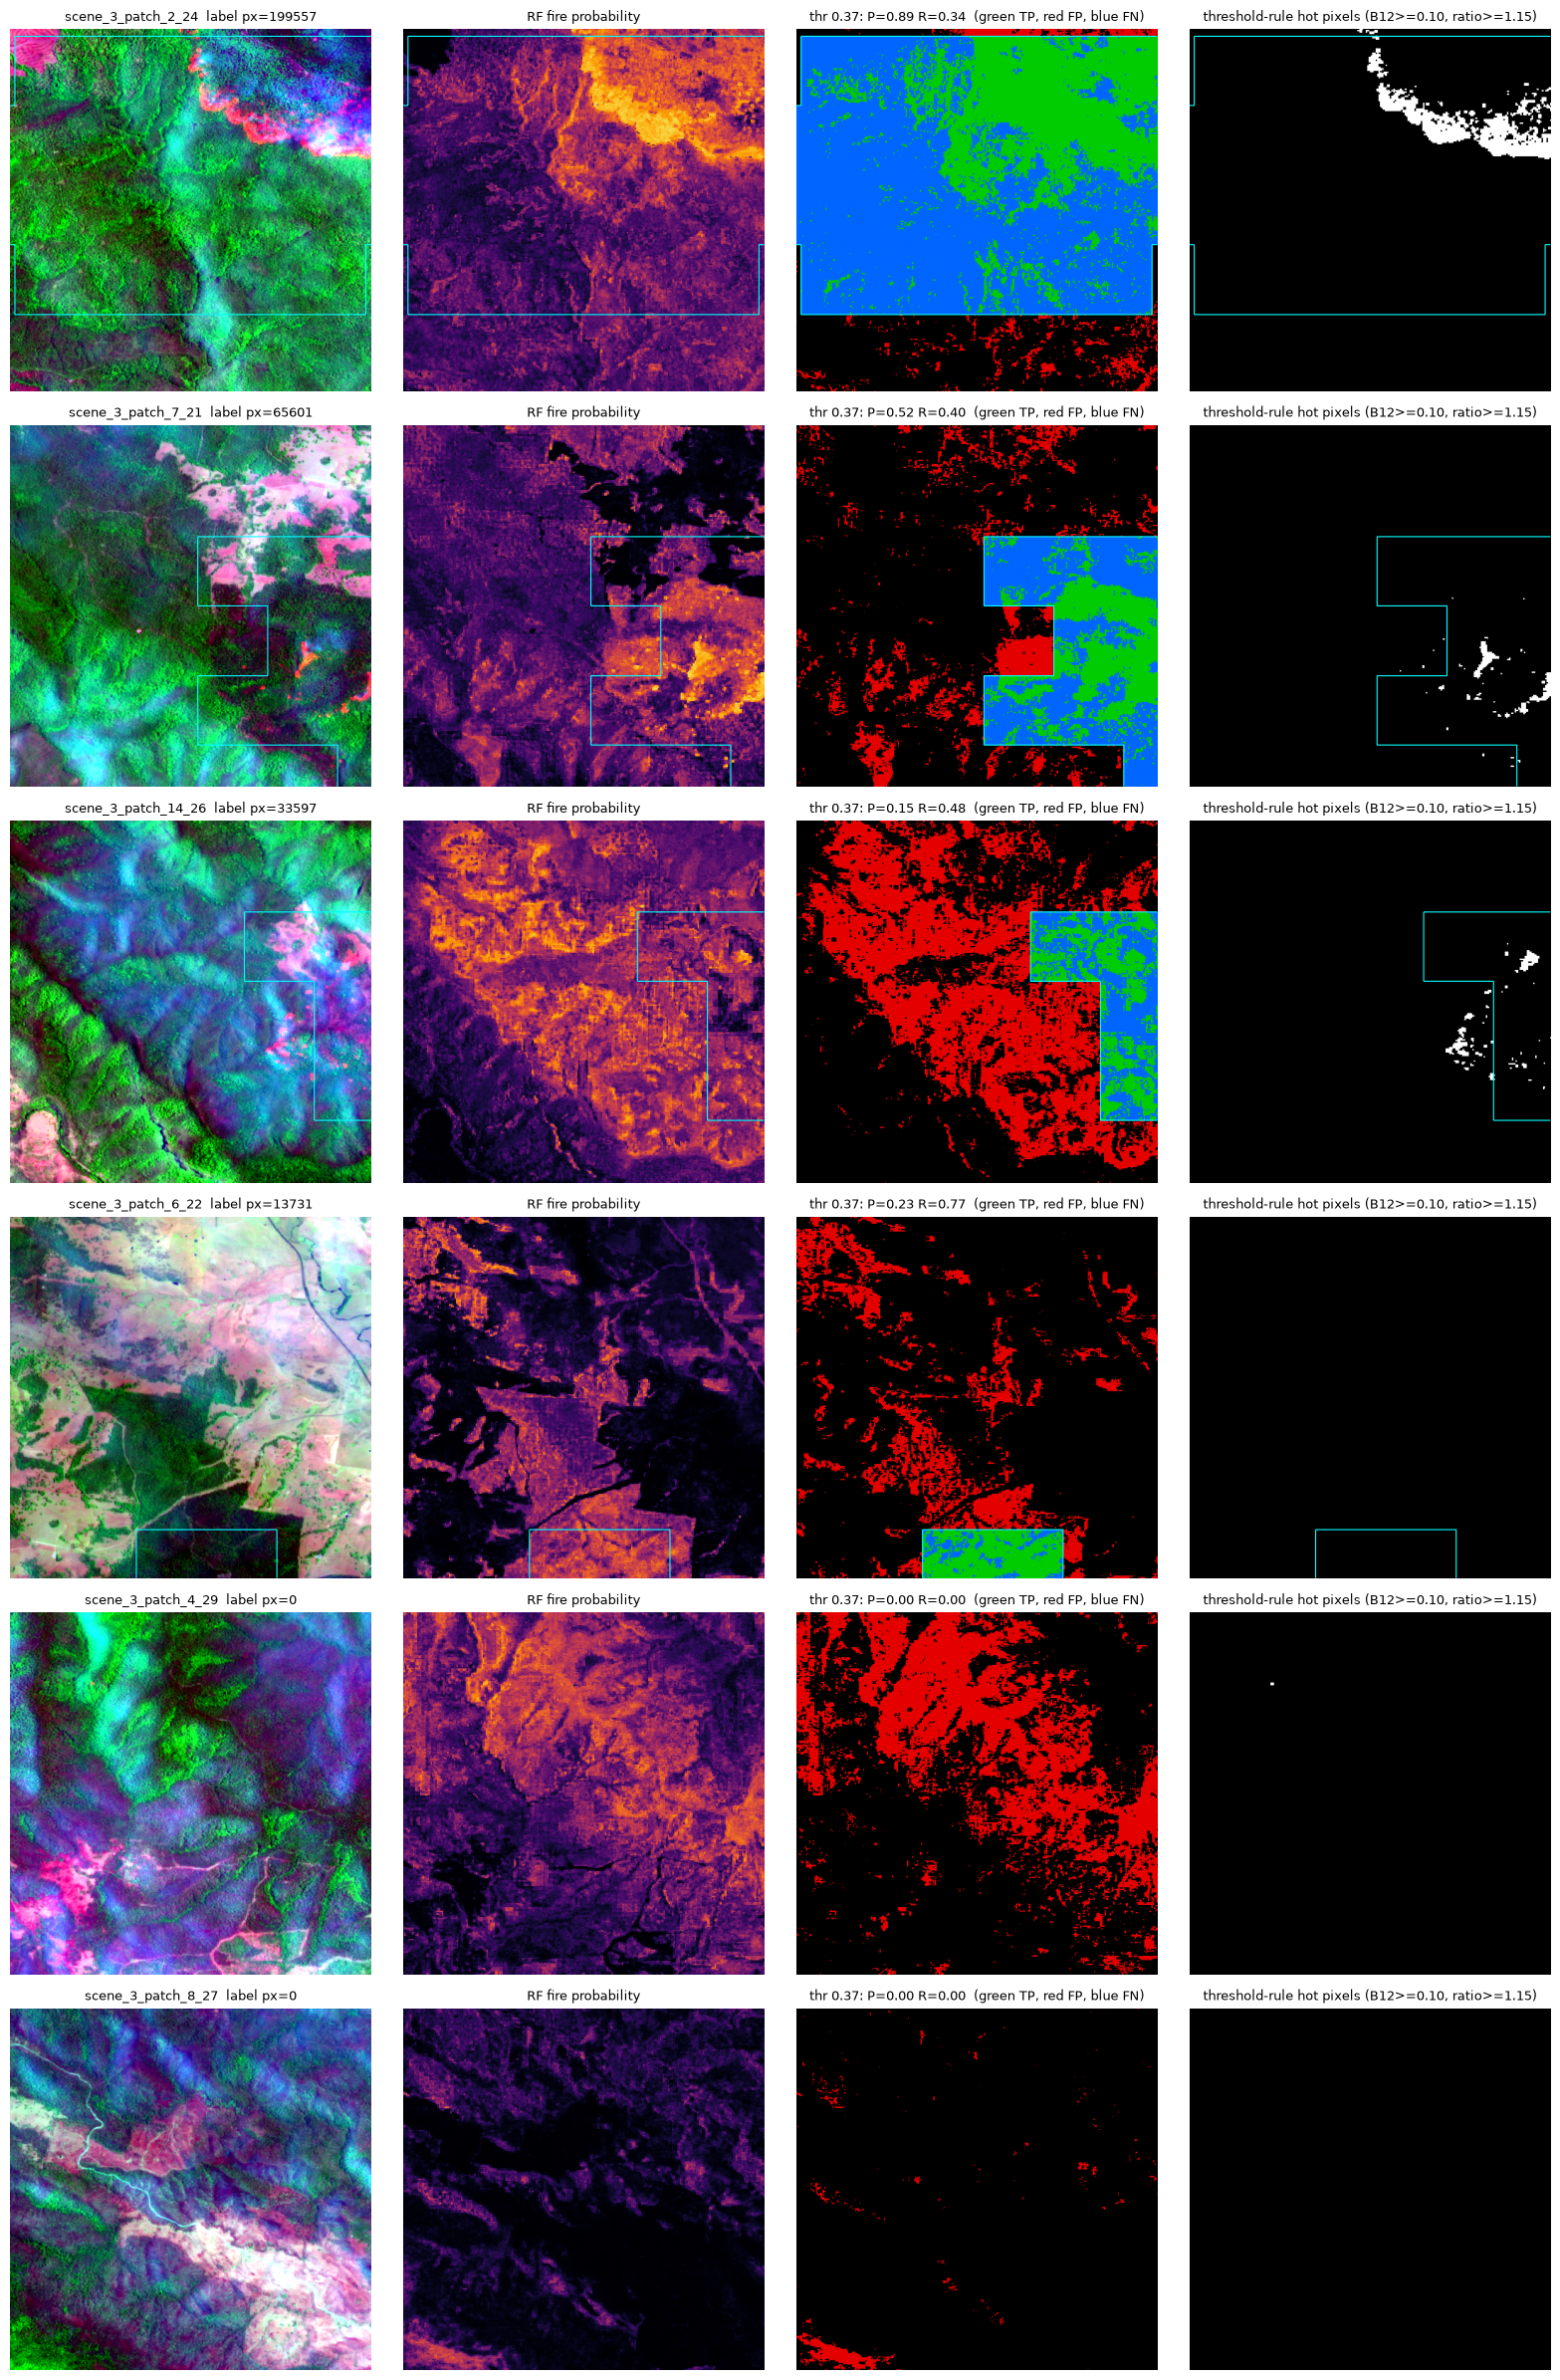

In [8]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

THR = 0.37
cols = list(range(13))

s = np.load(RF_PATH)
rf13 = RandomForestClassifier(n_estimators=100, max_depth=20, min_samples_leaf=10,
                              max_samples=0.3, n_jobs=-1, random_state=0)
rf13.fit(s["Xtr"][:, cols], s["ytr"])

pva_px = np.load(HIST_PATH)["pva"]
order = np.argsort(pva_px)
fire_ids = [int(i) for i in order if pva_px[i] > 0]
nonfire_ids = [int(i) for i in order if pva_px[i] == 0]
q = lambda a, f: a[int(f * (len(a) - 1))]
picks = [q(fire_ids, 1.0), q(fire_ids, 0.75), q(fire_ids, 0.5), q(fire_ids, 0.25),
         nonfire_ids[len(nonfire_ids) // 3], nonfire_ids[2 * len(nonfire_ids) // 3]]

def stretch_rgb(rgb):
    out = np.zeros_like(rgb)
    for c in range(3):
        lo, hi = np.percentile(rgb[..., c], [2, 98])
        out[..., c] = np.clip((rgb[..., c] - lo) / (hi - lo + 1e-6), 0, 1)
    return out

fig, axes = plt.subplots(len(picks), 4, figsize=(16, 4 * len(picks)))
for r, i in enumerate(picks):
    rel = splits["val"][i]
    with np.load(EXTRACT_DIR / rel) as d_:
        img = d_["image"]
        lb = d_["label"] > 0
    X = img.reshape(12, -1).astype(np.float32)
    feats = np.hstack([X.T, (X[11] / np.maximum(X[10], 1.0))[:, None]])
    prob = rf13.predict_proba(feats[:, cols])[:, 1].reshape(512, 512)
    pred = prob >= THR

    b11, b12 = img[10] / 1e4, img[11] / 1e4
    hot = (b11 > 0.05) & (b12 >= 0.10) & (b12 / np.maximum(b11, 1e-6) >= 1.15)

    comp = stretch_rgb(np.stack([img[11], img[7], img[3]], -1).astype(np.float32))
    err = np.zeros((512, 512, 3))
    err[pred & lb] = (0.0, 0.8, 0.0)
    err[pred & ~lb] = (0.9, 0.0, 0.0)
    err[~pred & lb] = (0.0, 0.4, 1.0)

    TP, FP, FN = int((pred & lb).sum()), int((pred & ~lb).sum()), int((~pred & lb).sum())
    prec, rec = TP / max(TP + FP, 1), TP / max(TP + FN, 1)

    axes[r, 0].imshow(comp)
    axes[r, 1].imshow(prob, cmap="inferno", vmin=0, vmax=1)
    axes[r, 2].imshow(err)
    axes[r, 3].imshow(hot, cmap="gray")
    for c in range(4):
        if lb.any():
            axes[r, c].contour(lb, levels=[0.5], colors="cyan", linewidths=0.8)
        axes[r, c].axis("off")
    name = rel.split("/")[-1].replace(".npz", "")
    axes[r, 0].set_title(f"{name}  label px={int(lb.sum())}", fontsize=9)
    axes[r, 1].set_title("RF fire probability", fontsize=9)
    axes[r, 2].set_title(f"thr {THR}: P={prec:.2f} R={rec:.2f}  (green TP, red FP, blue FN)", fontsize=9)
    axes[r, 3].set_title("threshold-rule hot pixels (B12>=0.10, ratio>=1.15)", fontsize=9)

plt.tight_layout()
plt.savefig(PROJECT_DIR / "results" / "rf_examples_val.png", dpi=110)
plt.show()

In [9]:
def pixel_table(i):
    rel = splits["val"][i]
    with np.load(EXTRACT_DIR / rel) as d_:
        img = d_["image"].astype(np.float32)
        lb = (d_["label"] > 0).ravel()
        aer = d_["aerosol"].ravel()
    X = img.reshape(12, -1)
    feats = np.hstack([X.T, (X[11] / np.maximum(X[10], 1.0))[:, None]])
    pred = rf13.predict_proba(feats)[:, 1] >= THR
    r = img / 1e4
    red, nir, s1, s2 = r[3].ravel(), r[7].ravel(), r[10].ravel(), r[11].ravel()
    tab = np.stack([red, nir, s1, s2,
                    s2 / np.maximum(s1, 1e-4),
                    (nir - red) / (nir + red + 1e-6),
                    (nir - s2) / (nir + s2 + 1e-6),
                    aer], axis=1)
    return tab, lb, pred

cols_t = ["red", "nir", "swir1", "swir2", "B12/B11", "NDVI", "NBR", "aerosol"]
groups = {k: [] for k in ["FP 14_26", "FP 4_29", "TP (fire patches)", "FN (fire patches)", "TN (all 6)"]}
rng_t = np.random.default_rng(0)

for k, i in enumerate(picks):
    tab, lb, pred = pixel_table(i)
    print(k, splits["val"][i].split("/")[-1])
    if k == 2: groups["FP 14_26"].append(tab[pred & ~lb])
    if k == 4: groups["FP 4_29"].append(tab[pred & ~lb])
    if k < 4:
        groups["TP (fire patches)"].append(tab[pred & lb])
        groups["FN (fire patches)"].append(tab[~pred & lb])
    tn = tab[~pred & ~lb]
    groups["TN (all 6)"].append(tn[rng_t.choice(len(tn), size=min(50000, len(tn)), replace=False)])

print(f"\n{'group':20s} {'n':>8s} " + " ".join(f"{c:>8s}" for c in cols_t))
for g, arrs in groups.items():
    A = np.vstack(arrs)
    med = np.median(A, axis=0)
    print(f"{g:20s} {len(A):8d} " + " ".join(f"{m:8.3f}" for m in med))

0 scene_3_patch_2_24.npz
1 scene_3_patch_7_21.npz
2 scene_3_patch_14_26.npz
3 scene_3_patch_6_22.npz
4 scene_3_patch_4_29.npz
5 scene_3_patch_8_27.npz

group                       n      red      nir    swir1    swir2  B12/B11     NDVI      NBR  aerosol
FP 14_26                92065    0.132    0.203    0.185    0.106    0.569    0.221    0.316    1.303
FP 4_29                 79470    0.107    0.184    0.130    0.086    0.672    0.273    0.366    1.396
TP (fire patches)      120987    0.104    0.199    0.126    0.085    0.665    0.292    0.374    2.911
FN (fire patches)      191499    0.087    0.203    0.139    0.073    0.520    0.397    0.464    2.816
TN (all 6)             300000    0.117    0.201    0.183    0.114    0.623    0.258    0.248    1.396


In [10]:
stats = {}
t0 = time.perf_counter()
for split in ["train", "val"]:
    for rel in splits[split]:
        with np.load(EXTRACT_DIR / rel) as d_:
            a = float(np.median(d_["aerosol"]))
            f = bool((d_["label"] > 0).any())
        stats.setdefault((rel.split("/")[0], f), []).append(a)
print(f"{time.perf_counter() - t0:.0f} s")
print(f"{'scene':8s} {'fire':5s} {'patches':>8s} {'median':>8s} {'p10':>8s} {'p90':>8s}")
for (sc, f), v in sorted(stats.items()):
    v = np.array(v)
    print(f"{sc:8s} {str(f):5s} {len(v):8d} {np.median(v):8.2f} {np.percentile(v,10):8.2f} {np.percentile(v,90):8.2f}")

42 s
scene    fire   patches   median      p10      p90
scene1   False      749    -0.77    -1.33     3.61
scene1   True       115     1.14    -0.67     5.63
scene2   False      556    -0.33    -1.30     0.77
scene2   True        38    -0.18    -1.06     0.91
scene3   False      410     0.67    -1.05     3.13
scene3   True        94     2.33     0.03     3.82
